# 7. En qué items falla

Cada item de train se predice con un modelo que no lo vio. Esas predicciones las calcula y guarda `python correr.py errores`, porque entrenar tarda, y este notebook las lee y las analiza.

El análisis sirve para buscar ideas nuevas, pero mirarlo también es una forma de sobreajustar. Por eso, cualquier idea que salga de acá se valida con folds nuevos antes de adoptarla.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")  # Los módulos están en la raíz del proyecto
warnings.filterwarnings("ignore")
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import datos
import modelo

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.constrained_layout.use"] = True  # Acomoda solo el espacio entre gráficos
COLOR_USADO, COLOR_NEUTRO = "#c0392b", "#7f8c8d"

train, _ = datos.construir(*datos.cargar_train_test())
predicciones = pd.read_parquet(datos.OUTPUTS / "errores" / "predicciones_validacion.parquet")
items = train.join(predicciones.drop(columns=["y"])).assign(y=modelo.y_binario(train))
items["prediccion"] = (items["proba_usado"] > 0.5).astype(int)  # Corte en 0.5 (D52)
items["error"] = items["prediccion"] != items["y"]
items["confianza"] = np.maximum(items["proba_usado"], 1 - items["proba_usado"])
errores = items[items["error"]]

def desglose(df, grupos):
    """Items, tasa de error y porcentaje del total de errores de cada grupo."""
    tabla = df.groupby(grupos, dropna=False, observed=True).agg(
        items=("error", "size"), errores=("error", "sum"), tasa_de_error=("error", "mean"))
    tabla["% de los items"] = 100 * tabla["items"] / len(df)
    tabla["% de los errores"] = 100 * tabla["errores"] / df["error"].sum()
    tabla.index = tabla.index.astype(str)
    return tabla[["items", "% de los items", "tasa_de_error", "errores", "% de los errores"]]

## Resumen

In [2]:
pd.crosstab(items["y"].map({0: "new", 1: "used"}), items["prediccion"].map({0: "new", 1: "used"}),
            rownames=["etiqueta"], colnames=["predicción"], margins=True, margins_name="total")

predicción,new,used,total
etiqueta,,,
new,35365,2223,37588
used,1488,30924,32412
total,36853,33147,70000


Sobre los 70.000 items de train el accuracy es 0,9470, con 3.711 errores. De esos, 2.223 son nuevos predichos como usados y 1.488 son usados predichos como nuevos.

## Cuánto se conoce al vendedor

La primera tabla agrupa según cuántos otros items con etiqueta tenía el vendedor al momento de validar. La segunda, según cuántos items tiene en total, contando train y test.

,items,% de los items,tasa_de_error,errores,% de los errores
vendedor_conocido,,,,,
ninguno,21580,30.829,0.099,2126,57.289
1 o 2,11639,16.627,0.049,566,15.252
3 a 5,7424,10.606,0.030,224,6.036
6 a 20,13368,19.097,0.034,456,12.288
más de 20,15989,22.841,0.021,339,9.135


,items,% de los items,tasa_de_error,errores,% de los errores
tamano_vendedor,,,,,
1 (único item),17503,25.004,0.104,1814,48.882
2,6524,9.320,0.069,450,12.126
3 a 5,9087,12.981,0.043,393,10.590
6 a 20,14509,20.727,0.034,495,13.339
más de 20,22377,31.967,0.025,559,15.063


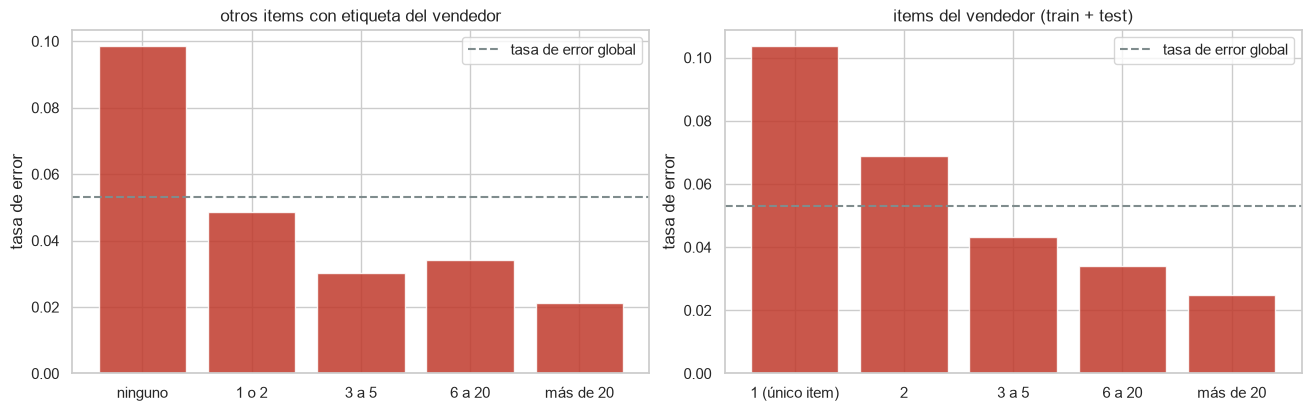

In [3]:
items["vendedor_conocido"] = pd.cut(items["te_seller_id_n"], [-1, 0, 2, 5, 20, np.inf],
                                    labels=["ninguno", "1 o 2", "3 a 5", "6 a 20", "más de 20"])
items["tamano_vendedor"] = pd.cut(items["seller_n_items"], [0, 1, 2, 5, 20, np.inf],
                                  labels=["1 (único item)", "2", "3 a 5", "6 a 20", "más de 20"])
conocido = desglose(items, "vendedor_conocido")
tamano = desglose(items, "tamano_vendedor")
display(conocido.round(3), tamano.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for tabla, ax, titulo in [(conocido, ejes[0], "otros items con etiqueta del vendedor"),
                          (tamano, ejes[1], "items del vendedor (train + test)")]:
    ax.bar(tabla.index, tabla["tasa_de_error"], color=COLOR_USADO, alpha=0.85)
    ax.axhline(items["error"].mean(), color=COLOR_NEUTRO, ls="--", label="tasa de error global")
    ax.set(title=titulo, ylabel="tasa de error")
    ax.legend()
plt.show()

**El modelo falla sobre todo donde no conoce al vendedor.** Los items cuyo vendedor no tiene ningún otro item con etiqueta son el 31% de los datos y concentran el 57% de los errores, con una tasa de error de 9,9%. La mayoría son vendedores de un único item (17.503 items, 10,4% de error). Para ellos no hay otras publicaciones en las que apoyarse, y solo queda lo que dice la propia publicación.

## Confianza del modelo

In [4]:
MUY_SEGURO = 0.9
tramos = pd.cut(items["confianza"], [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True)
display(desglose(items.assign(tramo_de_confianza=tramos), "tramo_de_confianza").round(3))

seguros = items[items["confianza"] > MUY_SEGURO]
pd.DataFrame({"valor": {
    "error que espera el modelo por su confianza": f"{np.minimum(items['proba_usado'], 1 - items['proba_usado']).mean():.1%}",
    "error real": f"{items['error'].mean():.1%}",
    "error cuando está muy seguro (más de 90%)": f"{seguros['error'].mean():.1%}",
    "errores con el modelo muy seguro": f"{seguros['error'].sum():,}",
    "fracción de todos los errores": f"{seguros['error'].sum() / len(errores):.0%}",
}})

,items,% de los items,tasa_de_error,errores,% de los errores
tramo_de_confianza,,,,,
"(0.499, 0.6]",658,0.940,0.508,334,9.000
"(0.6, 0.7]",738,1.054,0.425,314,8.461
"(0.7, 0.8]",955,1.364,0.396,378,10.186
"(0.8, 0.9]",1506,2.151,0.311,469,12.638
"(0.9, 1.0]",66143,94.490,0.034,2216,59.714


,valor
error que espera el modelo por su confianza,1.8%
error real,5.3%
error cuando está muy seguro (más de 90%),3.4%
errores con el modelo muy seguro,"2,216"
fracción de todos los errores,60%


El modelo se cree más seguro de lo que es. Por su confianza esperaría 1,8% de error, y el real es 5,3%. Cuando está muy seguro (más de 90%) falla el 3,4%. Como casi todos los items caen en ese tramo, esos fallos son 2.216, el 60% de todos los errores.

## Errores con el modelo muy seguro

In [5]:
ejemplos = errores.sort_values("confianza", ascending=False).head(20)
pd.DataFrame({
    "título": ejemplos["title"].str.slice(0, 55),
    "etiqueta": ejemplos["condition"],
    "proba usado": ejemplos["proba_usado"].round(3),
    "stock inicial": ejemplos["initial_quantity"],
    "tipo": ejemplos["listing_type_id"],
    "garantía": ejemplos["warranty"].fillna("").str.replace(r"\s+", " ", regex=True).str.slice(0, 30),
}).reset_index(drop=True)

,título,etiqueta,proba usado,stock inicial,tipo,garantía
0,Bisel Marco Frontal De Carcasa Lg G Pro E980 E...,used,0.0,900,bronze,si
1,Pedal De Afinador Behringer Tu300 Cromatico Gu...,used,0.0,1,bronze,Sí
2,Hidrolavadora Hyew65-1600 Outlet Oferta Hyunda...,used,0.0,10,silver,6 meses
3,Cilindros Fichet (cambio De Combinacion)#,used,0.0,3,bronze,De por vida
4,100 Soldaditos De Guerra Plasticos Souvenirs J...,used,0.0,499,bronze,
5,Toner Hp Q6002a Original Vacío 124a Amar. 1er ...,used,0.0,17,bronze,
6,Libro Digital - El Creador - Eduardo Zannini -...,used,0.0,10,silver,Sin garantía
7,Mercedes Benz Clase C 2007,new,1.0,1,gold_premium,
8,Cruz Lisa De Acero Con Cadena - Ben Junot - V...,used,0.0,20,bronze,
9,"Preparacion Para El Choque Pachter, Henry (ar...",new,1.0,1,bronze,Sí


Muchos de estos casos parecen etiquetas dudosas más que errores del modelo. Hay repuestos y consumibles con cientos de unidades de stock marcados como usados, "libros digitales" con stock múltiple marcados como usados, o autos de varios años marcados como nuevos. La condición la declara el vendedor y no siempre la carga bien. Esto pone un techo al accuracy que ningún modelo puede superar.

## Rol del item dentro de su vendedor

Un vendedor es "casi puro" si tiene 5 o más items con etiqueta y al menos el 80% son de la misma clase.

In [6]:
MIN_ITEMS, PUREZA = 5, 0.8
por_vendedor = items.groupby("seller_id")["y"].agg(["mean", "size"])
tasa_vendedor = items["seller_id"].map(por_vendedor["mean"])
items_vendedor = items["seller_id"].map(por_vendedor["size"])
es_minoria = ((tasa_vendedor >= PUREZA) & (items["y"] == 0)) | ((tasa_vendedor <= 1 - PUREZA) & (items["y"] == 1))
items["rol_en_el_vendedor"] = np.select(
    [items_vendedor < MIN_ITEMS, es_minoria, tasa_vendedor.between(1 - PUREZA, PUREZA, inclusive="neither")],
    ["vendedor con pocos items", "minoría de un vendedor casi puro", "vendedor mixto"],
    default="mayoría de un vendedor casi puro",
)
desglose(items, "rol_en_el_vendedor").round(3)

,items,% de los items,tasa_de_error,errores,% de los errores
rol_en_el_vendedor,,,,,
mayoría de un vendedor casi puro,30958,44.226,0.003,79,2.129
minoría de un vendedor casi puro,701,1.001,0.582,408,10.994
vendedor con pocos items,34234,48.906,0.079,2705,72.891
vendedor mixto,4107,5.867,0.126,519,13.985


Los items que son la excepción de su vendedor (el único usado de un comercio, o el único nuevo de un particular) fallan el 58% de las veces, porque la señal más fuerte del modelo apunta justo en la dirección contraria.

## Tipo de publicación y stock

In [7]:
display(desglose(items, "listing_type_id").round(3))
desglose(items.assign(stock_inicial=np.where(items["iq_es_1"], "1 unidad", "más de 1")), "stock_inicial").round(3)

,items,% de los items,tasa_de_error,errores,% de los errores
listing_type_id,,,,,
bronze,44143,63.061,0.058,2569,69.227
free,15047,21.496,0.056,844,22.743
gold,1713,2.447,0.016,28,0.755
gold_premium,587,0.839,0.017,10,0.269
gold_pro,13,0.019,0.000,0,0.000
gold_special,2134,3.049,0.001,2,0.054
silver,6363,9.090,0.041,258,6.952


,items,% de los items,tasa_de_error,errores,% de los errores
stock_inicial,,,,,
1 unidad,49156,70.223,0.069,3382,91.134
más de 1,20844,29.777,0.016,329,8.866


Con más de una unidad casi no hay errores. El problema está en las publicaciones `bronze` de una sola unidad, que pueden ser tanto de un comercio como de un particular.

## Categorías con más errores

In [8]:
categorias = items.groupby("category_id").agg(
    items=("error", "size"), errores=("error", "sum"), tasa_de_error=("error", "mean"), tasa_de_usados=("y", "mean"),
).sort_values("errores", ascending=False).head(12)
categorias["ejemplo"] = [items.loc[items["category_id"] == c, "title"].iloc[0][:45] for c in categorias.index]
categorias.round(3)

,items,errores,tasa_de_error,tasa_de_usados,ejemplo
category_id,,,,,
MLA1227,3180,82,0.026,0.508,Camino De La Perfeccion El - Dyer Wayne -nuev
MLA3530,542,64,0.118,0.402,Repuesto Pluma Parker Legítima Dorada
MLA2044,1359,62,0.046,0.746,El Huesped. Margarita Aguirre.
MLA41287,629,33,0.052,0.868,Aventuras De Robinson Crusoe - Daniel Defoe -
MLA15171,410,32,0.078,0.624,Alcatrazz Cd Dangerous Games
MLA4335,204,22,0.108,0.319,"Adorno, Tucán"
MLA1635,161,21,0.130,0.342,Cuadros Modernos Abstractos Tripticos
MLA15204,319,20,0.063,0.470,Adam Tully Guitar
MLA15226,184,19,0.103,0.576,Jimi Hendrix - West Coast Seattle Boy (cd + D
